# Multi-Class Benchmark Classification Pipeline

## Datheon – Machine Learning & Data Science Internship

### Objective
To build and compare supervised classification models
using the Iris flower dataset.

### Algorithms
1. Logistic Regression
2. Decision Tree Classifier

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

# Load the Iris dataset
df = pd.read_csv("iris.csv")

# Display first five records
print(df.head())

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSpecies Distribution:")
print(df["species"].value_counts())

Libraries imported successfully!
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
Dataset Shape: (150, 5)

Column Names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to understand the dataset,
identify patterns and examine relationships between features.


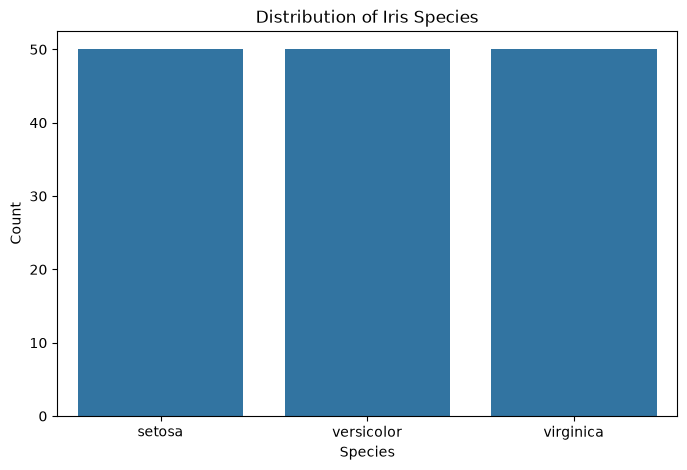

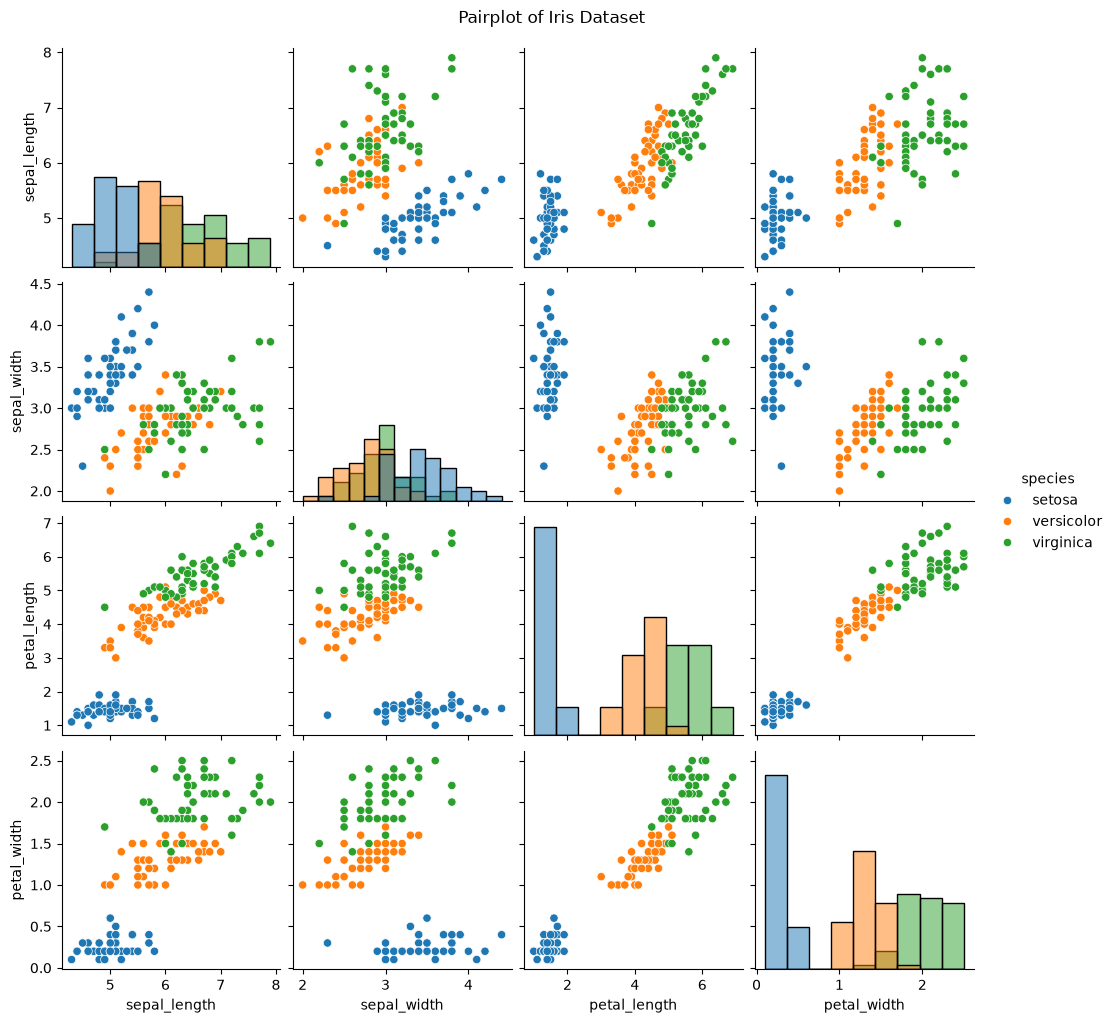

In [16]:
# Statistical summary of the dataset
df.describe()
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")

plt.show()

sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle(
    "Pairplot of Iris Dataset",
    y=1.02
)

plt.show()

## Feature Selection and Train-Test Split

The four flower measurements are selected as input features (X).

The species column is selected as the target variable (y).

The dataset is divided into:
- 80% Training Data
- 20% Testing Data

In [17]:
# Separate input features and target

X = df.drop("species", axis=1)
y = df["species"]

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Input Features:
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2

Target Variable:
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: str
Training Features: (120, 4)
Testing Features: (30, 4)
Training Target: (120,)
Testing Target: (30,)


## Feature Scaling using StandardScaler

StandardScaler is used to standardize the input features.

It transforms the features to have approximately:
- Mean = 0
- Standard Deviation = 1

The scaler is fitted only on the training data to prevent data leakage.

In [18]:
# Initialize StandardScaler

scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Training Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

Training Data Shape: (120, 4)
Testing Data Shape: (30, 4)


## Model Training

Two supervised machine learning algorithms are used:

1. Logistic Regression
2. Decision Tree Classifier

Both models are trained using the training dataset.

In [19]:
# Train Logistic Regression Model

lr_model = LogisticRegression(max_iter=200)

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

# Train Decision Tree Model

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train_scaled, y_train)

print("Decision Tree Model Trained Successfully!")

# Predict using Logistic Regression

lr_predictions = lr_model.predict(X_test_scaled)

# Predict using Decision Tree

dt_predictions = dt_model.predict(X_test_scaled)

print("Logistic Regression Predictions:")
print(lr_predictions)

print("\nDecision Tree Predictions:")
print(dt_predictions)

Logistic Regression Model Trained Successfully!
Decision Tree Model Trained Successfully!
Logistic Regression Predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']

Decision Tree Predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


## Model Evaluation

The trained classification models are evaluated using:

1. Accuracy
2. Precision
3. Recall
4. F1-Score

These metrics help compare the performance of both models.

In [20]:
# Evaluate Logistic Regression

lr_accuracy = accuracy_score(y_test, lr_predictions)
lr_precision = precision_score(y_test, lr_predictions, average="weighted")
lr_recall = recall_score(y_test, lr_predictions, average="weighted")
lr_f1 = f1_score(y_test, lr_predictions, average="weighted")

# Evaluate Decision Tree

dt_accuracy = accuracy_score(y_test, dt_predictions)
dt_precision = precision_score(y_test, dt_predictions, average="weighted")
dt_recall = recall_score(y_test, dt_predictions, average="weighted")
dt_f1 = f1_score(y_test, dt_predictions, average="weighted")

print("Logistic Regression")
print("Accuracy:", lr_accuracy)
print("Precision:", lr_precision)
print("Recall:", lr_recall)
print("F1-Score:", lr_f1)

print("\nDecision Tree")
print("Accuracy:", dt_accuracy)
print("Precision:", dt_precision)
print("Recall:", dt_recall)
print("F1-Score:", dt_f1)

# Compare model performance

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [lr_accuracy, dt_accuracy],
    "Precision": [lr_precision, dt_precision],
    "Recall": [lr_recall, dt_recall],
    "F1-Score": [lr_f1, dt_f1]
})

results

print("Logistic Regression Classification Report")

print(classification_report(y_test, lr_predictions))

print("\nDecision Tree Classification Report")

print(classification_report(y_test, dt_predictions))

Logistic Regression
Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1-Score: 0.9333333333333333

Decision Tree
Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1-Score: 0.9333333333333333
Logistic Regression Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   

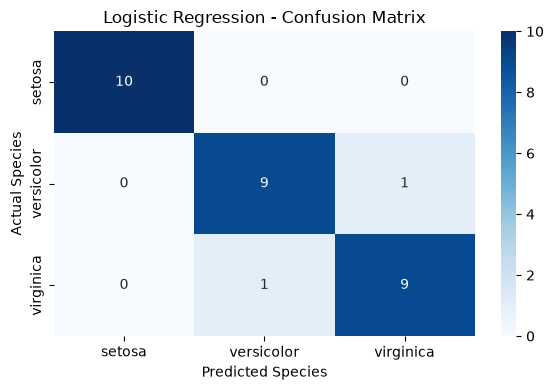

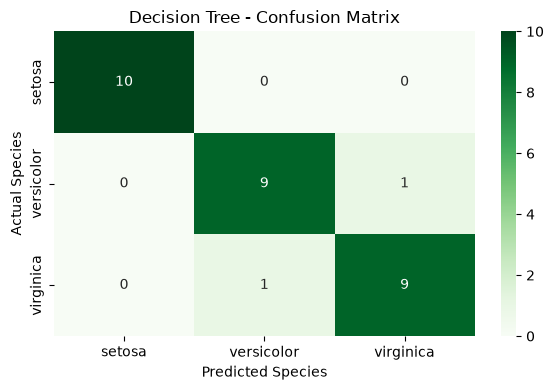

In [21]:
## Confusion Matrix

class_names = lr_model.classes_

lr_cm = confusion_matrix(y_test, lr_predictions, labels=class_names)

plt.figure(figsize=(6, 4))
sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

dt_cm = confusion_matrix(y_test, dt_predictions, labels=class_names)

plt.figure(figsize=(6, 4))
sns.heatmap(
    dt_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

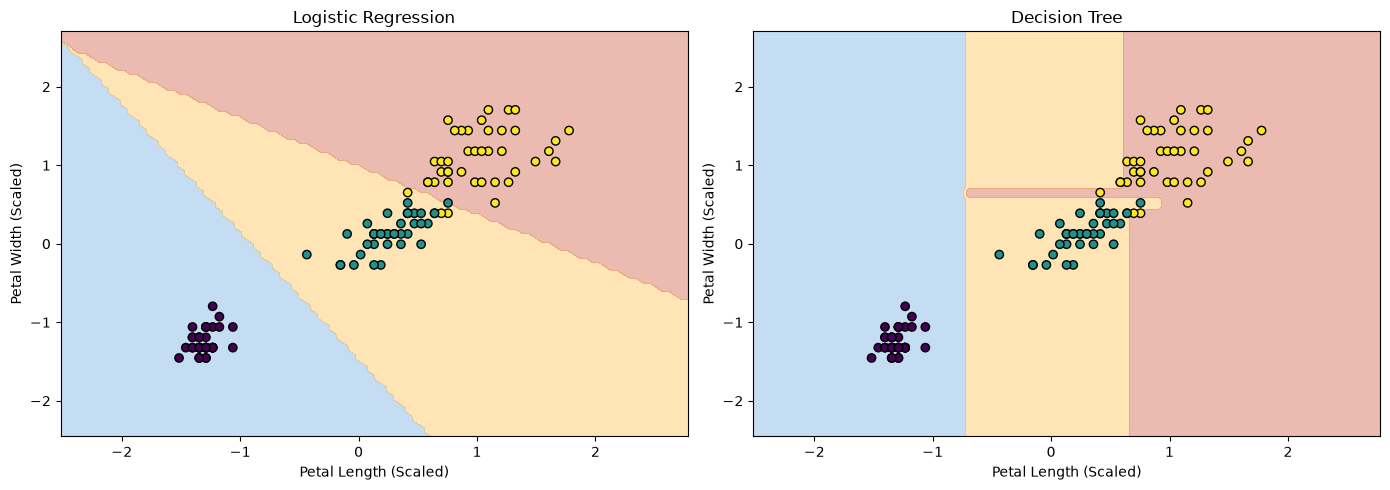

In [22]:
## Decision Boundary Visualization

from sklearn.inspection import DecisionBoundaryDisplay

X_2d = df[["petal_length", "petal_width"]]
y_2d = df["species"]

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)

lr_2d = LogisticRegression(max_iter=200)
lr_2d.fit(X_train_2d_scaled, y_train_2d)

dt_2d = DecisionTreeClassifier(random_state=42)
dt_2d.fit(X_train_2d_scaled, y_train_2d)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, title in [
    (axes[0], lr_2d, "Logistic Regression"),
    (axes[1], dt_2d, "Decision Tree")
]:
    DecisionBoundaryDisplay.from_estimator(
        model,
        X_train_2d_scaled,
        response_method="predict",
        ax=ax,
        xlabel="Petal Length (Scaled)",
        ylabel="Petal Width (Scaled)",
        alpha=0.3
    )

    ax.scatter(
        X_train_2d_scaled[:, 0],
        X_train_2d_scaled[:, 1],
        c=pd.Categorical(y_train_2d).codes,
        edgecolor="black"
    )

    ax.set_title(title)

plt.tight_layout()
plt.show()


## Conclusion

In this project, a multi-class classification pipeline was developed using the Iris dataset.

The dataset was explored and preprocessed using StandardScaler. The data was divided into training and testing sets using an 80:20 ratio.

Two machine learning algorithms were implemented:
1. Logistic Regression
2. Decision Tree Classifier

Both models achieved an accuracy of 93.33% on the test dataset. Their performance was evaluated using precision, recall, F1-score, classification reports, and confusion matrices.

Pairplot and decision boundary visualizations were also created to understand the distribution of the Iris species and how the models classify them.

### Final Result

Both Logistic Regression and Decision Tree performed well on the Iris dataset, achieving 93.33% accuracy.